# Prédiction des ventes chez Walmart

*Projet personnel de data science : du nettoyage et de la qualité des données jusqu'à la prédiction.*

## Contexte et objectif

Ce projet s'appuie sur les données de la compétition Kaggle [Walmart Recruiting – Store Sales Forecasting](https://www.kaggle.com/c/walmart-recruiting-store-sales-forecasting), dans une version où les ventes des différents départements sont regroupées par magasin.

**Objectif :** prédire les ventes hebdomadaires de 45 magasins Walmart à partir de 3 ans d'historique, et comprendre quels facteurs influencent réellement les ventes.

**Démarche :** chargement et fusion des données → contrôle qualité (doublons, types, valeurs manquantes) → imputation → analyse exploratoire → encodage → régression linéaire → feature engineering.

**Données :**

- fichier `data_w.csv`
    - `Store` : numéro du magasin
    - `Date` : semaine considérée
    - `Weekly_Sales` : ventes de la semaine (en $)
    - `Temperature` : température moyenne (en °F)
    - `Fuel_Price` : prix du carburant (en $)
    - `Markdown` : valeur moyenne des campagnes publicitaires (unité arbitraire)
    - `CPI` : [Consumer Price Index](https://www.bls.gov/cpi/), indice des prix à la consommation
    - `Unemployment` : taux de chômage
    - `IsHoliday` : semaine contenant un jour férié (vrai / faux)

- fichier `stores_w.csv`
    - `Store` : numéro du magasin
    - `Type` : type de magasin (A, B, C)
    - `Size` : surface
    - `People` : nombre d'employés

In [1]:
import pandas as pd 
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
SEED = 169

## 1 - Lecture des fichiers

Chargement des deux fichiers sources.

In [2]:
data = pd.read_csv('data_w.csv')
stores = pd.read_csv('stores_w.csv')
data.head()

,Store,Date,Weekly_Sales,Temperature,Fuel_Price,CPI,Unemployment,IsHoliday,Markdown
0,1,2010-02-05,1643690.90,42.31,2.572,211.096358,8.106,False,0.0
1,1,2010-02-12,1641957.44,38.51,2.548,211.242170,8.106,True,0.0
2,1,2010-02-19,1611968.17,39.93,2.514,211.289143,8.106,False,0.0
3,1,2010-02-26,1409727.59,46.63,2.561,211.319643,8.106,False,0.0
4,1,2010-03-05,1554806.68,46.50,2.625,211.350143,8.106,False,0.0


Taille des jeux de données :

In [3]:
print("Nombre d'exemples dans data :", data.shape[0])

Nombre d'exemples dans data : 6438


In [4]:
print("Nombre de magasins dans stores :", stores['Store'].nunique())
stores.head()

Nombre de magasins dans stores : 45


,Store,Type,Size,People
0,1,A,151315,40.0
1,2,A,202307,38.0
2,3,B,37392,12.0
3,4,A,205863,30.0
4,5,B,34875,8.0


**Constat :** `data` contient **6 438 lignes** (semaines × magasins) et `stores` décrit **45 magasins**.

Exemple de requête ciblée : température relevée la semaine du 28/09/2012 pour le magasin n°11.

In [5]:
data.loc[(data['Store'] == 11) & (data['Date'] == '2012-09-28'), ['Store', 'Date', 'Temperature']]

,Store,Date,Temperature
1569,11,2012-09-28,77.67


**Constat :** 77,67 °F, soit environ 25,4 °C. Les températures du jeu de données sont exprimées en degrés Fahrenheit (de −2 à 100 °F environ).

## 2 - Combinaison des données


On dispose d'une table `data` qui contient les ventes hebdomadaires et le contexte de chaque semaine, et d'une table `stores` qui décrit les magasins. Pour l'analyse, on les combine en une table unique.

**Choix de la méthode :** les deux tables partagent la clé `Store`. On veut ajouter à chaque ligne de `data` les caractéristiques du magasin correspondant, c'est-à-dire faire une **jointure** (comme un `JOIN` en SQL) : c'est le rôle de **`pd.merge`**. `pd.concat` se contenterait d'empiler les tableaux sans les aligner sur une clé.

Jointure sur la clé `Store`, puis vérification avec le fichier `df_w.csv`, qui contient les deux tables déjà fusionnées.

In [6]:
# Les deux tables partagent la colonne 'Store' : c'est la clé de jointure
print(data.columns.tolist())
print(stores.columns.tolist())

['Store', 'Date', 'Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'IsHoliday', 'Markdown']
['Store', 'Type', 'Size', 'People']


In [7]:
df = pd.merge(data, stores, on='Store', how='left')

In [8]:
# Vérification : on retrouve exactement le fichier df_w.csv (tables déjà fusionnées)
print(df.equals(pd.read_csv('df_w.csv')))
df.head()

True


,Store,Date,Weekly_Sales,Temperature,Fuel_Price,CPI,Unemployment,IsHoliday,Markdown,Type,Size,People
0,1,2010-02-05,1643690.90,42.31,2.572,211.096358,8.106,False,0.0,A,151315,40.0
1,1,2010-02-12,1641957.44,38.51,2.548,211.242170,8.106,True,0.0,A,151315,40.0
2,1,2010-02-19,1611968.17,39.93,2.514,211.289143,8.106,False,0.0,A,151315,40.0
3,1,2010-02-26,1409727.59,46.63,2.561,211.319643,8.106,False,0.0,A,151315,40.0
4,1,2010-03-05,1554806.68,46.50,2.625,211.350143,8.106,False,0.0,A,151315,40.0


**Constat :** la jointure donne exactement le même tableau que `df_w.csv`.

## 3 - Qualité des données

### Dimensions

In [9]:
print("Nombre de lignes   :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

Nombre de lignes   : 6438
Nombre de colonnes : 12


**Constat :** `df` contient **6 438 lignes** et **12 colonnes** : les 9 de `data`, plus `Type`, `Size` et `People`.

### Doublons

Recherche des lignes dupliquées, puis suppression.

In [10]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())

Nombre de lignes dupliquées : 3


In [11]:
# Affichage des lignes concernées (original + copie)
df[df.duplicated(keep=False)].sort_values(['Store', 'Date'])

,Store,Date,Weekly_Sales,Temperature,Fuel_Price,CPI,Unemployment,IsHoliday,Markdown,Type,Size,People
15,1,2010-05-21,1399662.07,76.44,2.826,210.617093,7.808,False,0.0,A,151315,40.0
16,1,2010-05-21,1399662.07,76.44,2.826,210.617093,7.808,False,0.0,A,151315,40.0
4933,35,2011-06-10,855130.21,73.26,3.881,138.860638,8.512,False,0.0,B,103681,44.0
4934,35,2011-06-10,855130.21,73.26,3.881,138.860638,8.512,False,0.0,B,103681,44.0
4935,35,2011-06-10,855130.21,73.26,3.881,138.860638,8.512,False,0.0,B,103681,44.0


In [12]:
df = df.drop_duplicates()
print("Lignes dupliquées restantes :", df.duplicated().sum())
print("Nouvelle taille de df :", df.shape)

Lignes dupliquées restantes : 0
Nouvelle taille de df : (6435, 12)


**Constat :** il y a **3 lignes dupliquées** : une copie de la ligne du magasin 1 au 21/05/2010 et deux copies de la ligne du magasin 35 au 10/06/2011. Après `drop_duplicates()`, il n'en reste aucune et `df` passe à **6 435 lignes**.

### Types des colonnes

In [13]:
df[['Date', 'Temperature', 'IsHoliday', 'Size']].dtypes

Date            object
Temperature    float64
IsHoliday         bool
Size             int64
dtype: object

**Constat :**
- `Date` : **object** (texte : pandas ne reconnaît pas automatiquement les dates à la lecture du CSV)
- `Temperature` : **float64**
- `IsHoliday` : **bool**
- `Size` : **int64**

### Valeurs manquantes

In [14]:
df.isna().sum()

Store           0
Date            0
Weekly_Sales    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
IsHoliday       0
Markdown        0
Type            0
Size            0
People          0
dtype: int64

In [15]:
print("Nombre total de valeurs manquantes :", df.isna().sum().sum())

Nombre total de valeurs manquantes : 0


**Constat :** le jeu de données d'origine ne contient **aucune valeur manquante**.

### Nature des variables

| Variable | Nature | Remarque |
|---|---|---|
| `Store` | qualitative | numéro = identifiant, pas une quantité |
| `Date` | ordinale | les dates sont ordonnées |
| `Weekly_Sales` | quantitative | variable à prédire |
| `Temperature` | quantitative | |
| `Fuel_Price` | quantitative | |
| `CPI` | quantitative | |
| `Unemployment` | quantitative | |
| `Markdown` | quantitative | |
| `IsHoliday` | qualitative | binaire |
| `Type` | qualitative | catégories A, B, C |
| `Size` | quantitative | |
| `People` | quantitative | |

La colonne `Date` est lue comme du texte : on la convertit en type date.

In [16]:
df['Date'] = df['Date'].apply(pd.to_datetime)

## 4 - Valeurs manquantes

Le jeu de données est complet. Pour reproduire une situation réelle où des données manquent, et pouvoir **évaluer les méthodes d'imputation en les comparant aux vraies valeurs**, on injecte volontairement 55 valeurs manquantes au hasard. La graine aléatoire est fixée pour que le résultat soit reproductible.

In [17]:
def addNans(df,nbNans, seed=None):
    # Randomly adds (less than) nbNans nans in df
    nx,ny = df.shape
    np.random.seed(seed)
    df2=df.copy()
    for k in range(nbNans):
        df2.iloc[np.random.randint(0,high=nx, size=1), 
                         np.random.randint(0, high=ny, size=1)] = np.nan
    return df2

In [18]:
df2 = addNans(df,55, seed=SEED)

nans = pd.isnull(df2).to_numpy().nonzero()
nan1 = nans[0][0], nans[1][0]
nan2 = nans[0][1], nans[1][1]
nan3 = nans[0][2], nans[1][2]

print(df.iloc[nan1], df.iloc[nan2], df.iloc[nan3])

3.353 151315 False


C:\Users\bibaw\AppData\Local\Temp\ipykernel_11788\3214694047.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  df2.iloc[np.random.randint(0,high=nx, size=1),


### 4.1 Valeurs manquantes injectées

In [19]:
print("NaN au total              :", df2.isna().sum().sum())
print("NaN dans 'Temperature'    :", df2['Temperature'].isna().sum())
print("NaN dans 'Type'           :", df2['Type'].isna().sum())
df2.isna().sum()

NaN au total              : 55
NaN dans 'Temperature'    : 1
NaN dans 'Type'           : 4


Store           3
Date            4
Weekly_Sales    1
Temperature     1
Fuel_Price      9
CPI             5
Unemployment    6
IsHoliday       7
Markdown        4
Type            4
Size            7
People          4
dtype: int64

**Constat :** **55 valeurs manquantes** au total, réparties dans toutes les colonnes : 1 dans `Temperature`, 4 dans `Type`, et même dans `Date` et `IsHoliday`.

In [20]:
# Position des nans (pour le test qui suit)
nans = pd.isnull(df2).to_numpy().nonzero()
nan1 = nans[0][0], nans[1][0]
nan2 = nans[0][1], nans[1][1]
nan3 = nans[0][2], nans[1][2]

In [21]:
print(df.iloc[nan1], df.iloc[nan2], df.iloc[nan3])

3.353 151315 False


### 4.2 Imputation

Stratégie en deux temps :
- **variables qualitatives** : remplacement par la valeur précédente (`ffill`). Les données étant triées par magasin puis par date, c'est presque toujours la valeur du même magasin la semaine d'avant ;
- **variables quantitatives** : imputation par les **5 plus proches voisins** (`KNNImputer`). L'imputeur KNN de scikit-learn ne fonctionne qu'avec des données numériques, d'où cette séparation.

In [22]:
quanti = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Markdown', 'Size', 'People']
quali = ['Store', 'Date', 'IsHoliday', 'Type']   # la date est traitée comme qualitative (ordinale) ici

### 4.2.1 Variables qualitatives

In [23]:
# Remplacement par la valeur précédente (forward fill). Les données étant triées par magasin puis par date,
# la valeur précédente est presque toujours celle du même magasin la semaine d'avant.
with pd.option_context('future.no_silent_downcasting', True):
    df2[quali] = df2[quali].ffill().infer_objects()   # équivalent moderne de fillna(method='ffill')

In [24]:
df2[quali].isna().sum()

Store        0
Date         0
IsHoliday    0
Type         0
dtype: int64

### 4.2.2 Variables quantitatives

**Normalisation.** Le KNN repose sur des distances : il faut d'abord standardiser les variables. Sinon, `Size` (≈ 100 000) écraserait complètement `Fuel_Price` (≈ 3) dans le calcul des distances.

In [25]:
from sklearn.preprocessing import StandardScaler

In [26]:
sc = StandardScaler()
sc.fit(df2[quanti])                      # les NaN sont ignorés pendant le calcul des moyennes / écarts-types
df2[quanti] = sc.transform(df2[quanti])

Contrôle de la standardisation sur deux valeurs (position `[1227, 'Temperature']` et `[2134, 'CPI']`) :

In [27]:
df2.loc[1227, 'Temperature']

np.float64(1.5541125913898075)

In [28]:
df2.loc[2134, 'CPI']

np.float64(-0.8494303607616269)

Après standardisation, la température à la position 1227 vaut **≈ 1,55** : elle est environ 1,5 écart-type au-dessus de la moyenne. Le CPI à la position 2134 vaut **≈ −0,85**.

Après l'imputation, on revient à l'échelle d'origine avec `sc.inverse_transform`, pour garder des valeurs interprétables (dollars, degrés…).

**Imputation et contrôle par rapport aux vraies valeurs**

In [29]:
from sklearn.impute import KNNImputer

In [30]:
impute = KNNImputer(missing_values = np.nan ,n_neighbors = 5)

In [31]:
impute.fit(df2[quanti])
df2[quanti] = impute.transform(df2[quanti])
df2[quanti] = sc.inverse_transform(df2[quanti])  # on se remet sur l'échelle initiale des données
print("NaN restants :", df2.isna().sum().sum())

NaN restants : 0


In [32]:
print("Le nan1, de valeur initiale {}, a été remplacé par {}".format(df.iloc[nan1], df2.iloc[nan1] ))


Le nan1, de valeur initiale 3.353, a été remplacé par 3.0656


In [33]:
print("Le nan2, de valeur initiale  {}, a été remplacé par {}".format(df.iloc[nan2], df2.iloc[nan2] ))

Le nan2, de valeur initiale  151315, a été remplacé par 151315.0


In [34]:
print("Le nan3, de valeur initiale  {}, a été remplacé par {}".format(df.iloc[nan3], df2.iloc[nan3] ))

Le nan3, de valeur initiale  False, a été remplacé par False


**Bilan de l'imputation :**
- `nan1` (`Fuel_Price`) : valeur réelle 3,353 $, valeur imputée par KNN ≈ 3,066 $. L'ordre de grandeur est bon, l'erreur est d'environ 9 %.
- `nan2` (`Size`) : valeur exactement retrouvée (151 315), car les 5 plus proches voisins sont des semaines du même magasin, qui a toujours la même surface.
- `nan3` (`IsHoliday`) : valeur retrouvée (`False`) par propagation de la valeur précédente (`ffill`).

L'imputation KNN fonctionne donc très bien pour les variables propres au magasin, et donne une approximation raisonnable pour les variables qui évoluent dans le temps.

## 5 - Analyse exploratoire

### 5.1 Matrice de corrélation

On considère uniquement les variables quantitatives


In [35]:
Quanti = df2[quanti].copy()

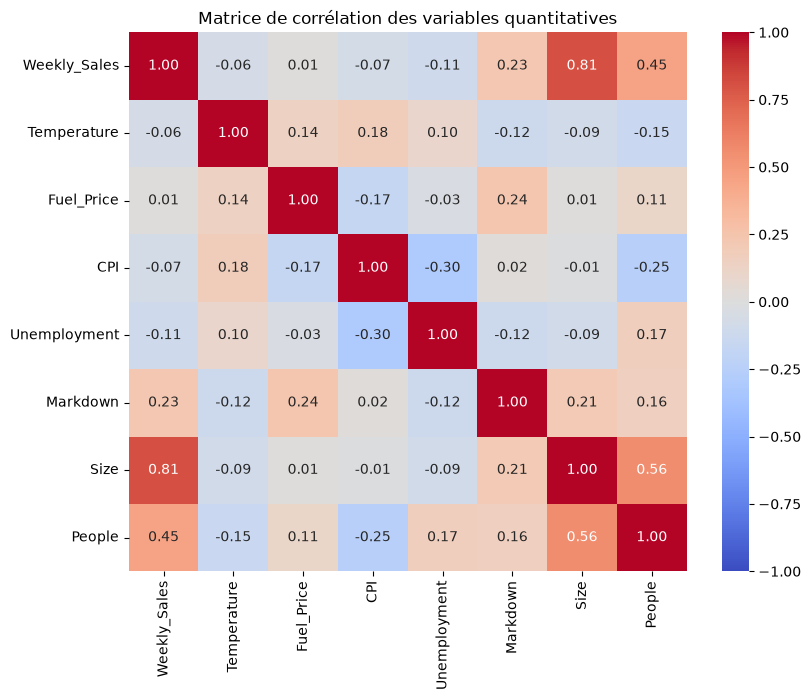

corr(Weekly_Sales, Size)         = 0.81
corr(Weekly_Sales, Unemployment) = -0.106
corr(CPI, Fuel_Price)            = -0.171


In [36]:
corr = Quanti.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matrice de corrélation des variables quantitatives')
plt.show()

print("corr(Weekly_Sales, Size)         =", round(corr.loc['Weekly_Sales', 'Size'], 3))
print("corr(Weekly_Sales, Unemployment) =", round(corr.loc['Weekly_Sales', 'Unemployment'], 3))
print("corr(CPI, Fuel_Price)            =", round(corr.loc['CPI', 'Fuel_Price'], 3))

**Constats :**
- `Weekly_Sales` et `Size` : **≈ 0,81**. C'est une forte corrélation positive : les grands magasins vendent plus.
- `Weekly_Sales` et `Unemployment` : **≈ −0,11**. Elle est faible : le chômage local influence peu les ventes.
- `CPI` et `Fuel_Price` : **≈ −0,17**. Elle est faible.

`People` (nombre d'employés) est modérément corrélé à `Size` (≈ 0,56) et aux ventes (≈ 0,45). Les autres variables quantitatives sont peu liées aux ventes.

### 5.2 Dépendances entre variables quantitatives et qualitatives

Ventes selon le type de magasin :

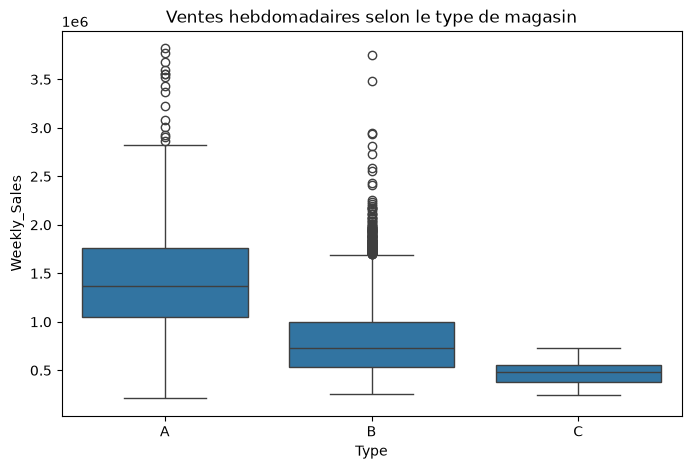

In [37]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Type', y='Weekly_Sales', data=df2, order=['A', 'B', 'C'])
plt.title('Ventes hebdomadaires selon le type de magasin')
plt.show()

3e quartile des ventes par type de magasin (en millions de $) :

In [38]:
(df2.groupby('Type')['Weekly_Sales'].quantile(0.75) / 1e6).round(3)   # 3e quartile, en millions

Type
A    1.759
B    0.997
C    0.556
Name: Weekly_Sales, dtype: float64

Médiane des ventes par type de magasin (en millions de $) :

In [39]:
(df2.groupby('Type')['Weekly_Sales'].median() / 1e6).round(3)   # médiane, en millions

Type
A    1.371
B    0.733
C    0.478
Name: Weekly_Sales, dtype: float64

**Constat :** les magasins de type A vendent nettement plus : médiane ≈ 1,37 M$ par semaine, contre ≈ 0,73 M$ pour le type B et ≈ 0,48 M$ pour le type C. Le 3e quartile du type B est d'environ 1 M$.

Taille des magasins selon leur type :

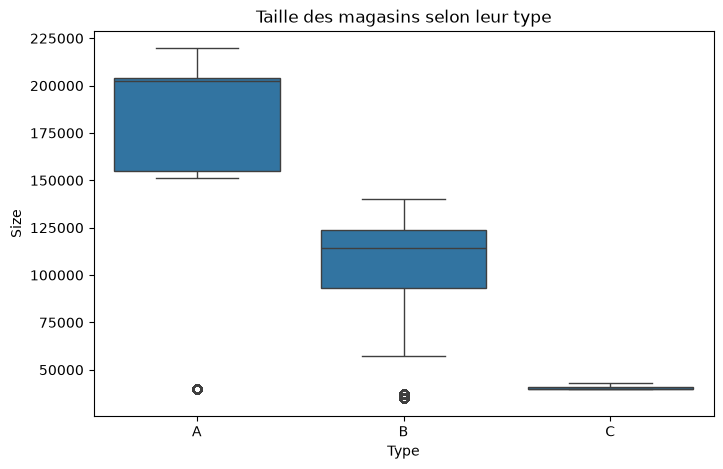

Type
A    202406.0
B    114533.0
C     39910.0
Name: Size, dtype: float64

In [40]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Type', y='Size', data=df2, order=['A', 'B', 'C'])
plt.title('Taille des magasins selon leur type')
plt.show()

df2.groupby('Type')['Size'].median()

Relation entre taille et type :

In [41]:
df2.groupby('Type')['Size'].describe()[['min', '25%', '50%', '75%', 'max']]

,min,25%,50%,75%,max
Type,,,,,
A,39690.0,155083.0,202406.0,203819.0,219622.0
B,34875.0,93188.0,114533.0,123737.0,140167.0
C,39690.0,39690.0,39910.0,41062.0,42988.0


**Constat :** la taille et le type sont **fortement liés**. Les trois types correspondent à des gammes de tailles bien séparées : A ≈ 200 000, B ≈ 115 000, C ≈ 40 000. Seuls quelques magasins atypiques de type A et B (≈ 35 000 – 40 000) recoupent la gamme du type C. Le type est donc en grande partie déterminé par la taille du magasin.

Effet des semaines de vacances (`IsHoliday`) sur les ventes :

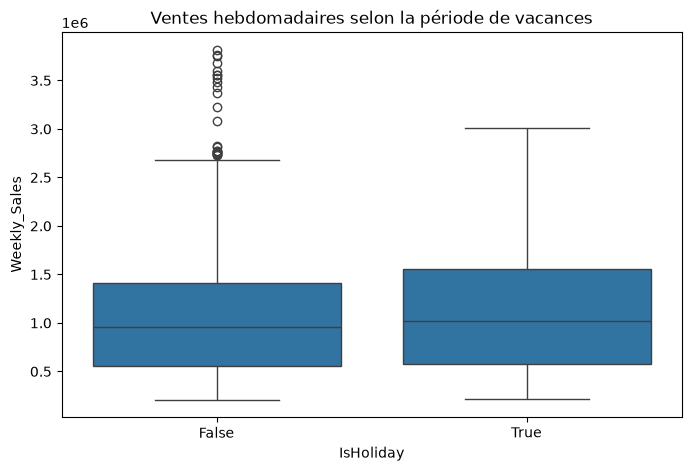

,mean,median
IsHoliday,,
False,1041184.0,956062.0
True,1123649.0,1021392.0


In [42]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='IsHoliday', y='Weekly_Sales', data=df2)
plt.title('Ventes hebdomadaires selon la période de vacances')
plt.show()

df2.groupby('IsHoliday')['Weekly_Sales'].agg(['mean', 'median']).round(0)

**Constat :** l'effet est **faible**. Les semaines de vacances ont des ventes légèrement plus élevées (moyenne ≈ 1,12 M$ contre 1,04 M$, soit environ +8 %), mais les boîtes à moustaches se recouvrent presque entièrement. `IsHoliday` regroupe des périodes très différentes (Super Bowl, fête du Travail, Thanksgiving, Noël), ce qui dilue son effet.

### 5.3 - Analyse temporelle

Évolution des ventes moyennes (tous magasins confondus) au cours du temps, avec `sns.lineplot` (moyenne et intervalle de confiance).

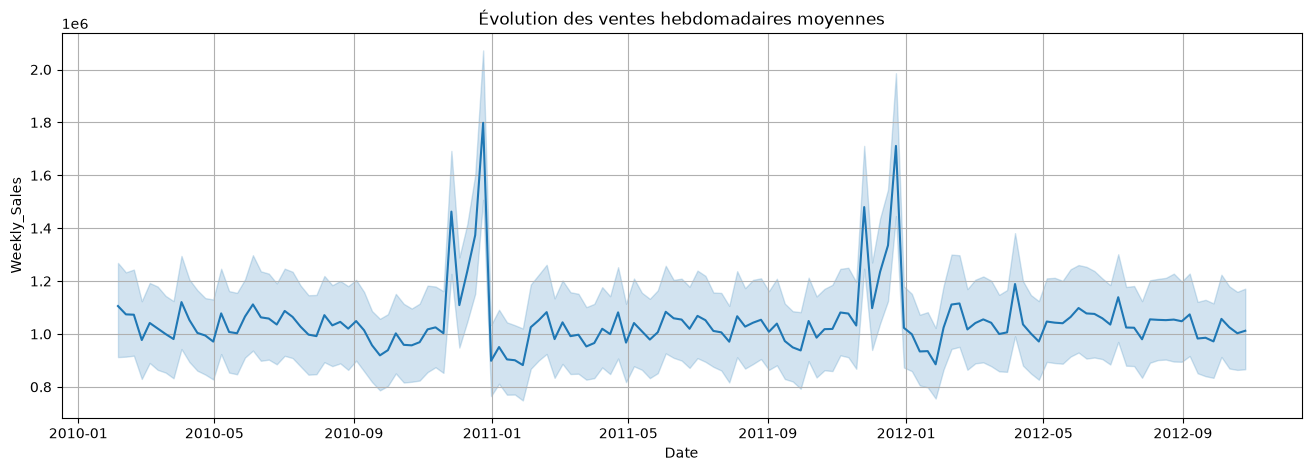

In [43]:
f, ax = plt.subplots(figsize=(16, 5))
sns.lineplot(x='Date', y='Weekly_Sales', data=df2, ax=ax)   # moyenne sur les magasins + intervalle de confiance
ax.set_title('Évolution des ventes hebdomadaires moyennes')
plt.grid()
plt.show()

**Constat :** les ventes sont globalement stables au fil de l'année, avec **deux pics nets chaque année** : la semaine de Thanksgiving / Black Friday (fin novembre) et surtout les semaines précédant Noël. Elles retombent ensuite en janvier, le mois le plus faible. Il n'y a pas de baisse marquée en été.

## 6 - Encodage des variables


### 6.1 Faut-il standardiser pour la régression ?

**Non, ce n'est pas indispensable** pour une régression linéaire classique (moindres carrés). Standardiser une variable revient à changer son unité : les coefficients s'adaptent, mais les prédictions et le R² restent identiques. La standardisation serait en revanche nécessaire pour comparer directement l'importance des coefficients, ou pour une régression pénalisée (Ridge, Lasso) ou un KNN, qui sont sensibles aux échelles.

On garde donc les variables quantitatives sur leur échelle d'origine, ce qui permet d'interpréter les résultats en dollars.

**Variables qualitatives**

In [44]:
# Variables qualitatives à encoder : Store, Type et IsHoliday (la date est traitée à part en 6.2)
df2[['Store', 'Type', 'IsHoliday']].head()

,Store,Type,IsHoliday
0,1.0,A,False
1,1.0,A,True
2,1.0,A,False
3,1.0,A,False
4,1.0,A,False


### 6.2 Encodage de la date

La date est décomposée en année, mois, semaine et jour, pour que le modèle puisse exploiter la saisonnalité.

In [45]:
dfDate = pd.DataFrame()
dfDate['Year']=df2['Date'].dt.year
dfDate['Month']=df2['Date'].dt.month
dfDate['Week']=df2['Date'].dt.isocalendar().week
dfDate['Day']=df2['Date'].dt.day

### 6.3 Encodage one-hot

`Store`, `Type` et `IsHoliday` sont encodées en one-hot avec `pd.get_dummies`.

In [46]:
df2['Store'] = df2['Store'].astype(int).astype('category')   ## par précaution. Sinon il ne le reconnait pas forcément comme une catégorie
df2['IsHoliday'] = df2['IsHoliday'].astype(bool).astype('category')

In [47]:
Quali = pd.get_dummies(df2[['Store', 'Type', 'IsHoliday']]).astype(int)

In [48]:
print(Quali.shape)
Quali.head()

(6435, 50)


,Store_1,Store_2,Store_3,Store_4,Store_5,Store_6,Store_7,Store_8,Store_9,Store_10,...,Store_41,Store_42,Store_43,Store_44,Store_45,Type_A,Type_B,Type_C,IsHoliday_False,IsHoliday_True
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0


`Quali` contient **50 colonnes** : 45 pour `Store`, 3 pour `Type` et 2 pour `IsHoliday`.

## 7 - Régression linéaire

### 7.1 Fonction d'évaluation

Cette fonction reçoit un tableau et le nom de la variable à prédire. Elle sépare les données en apprentissage et test (80 / 20), entraîne une régression linéaire et renvoie :
- le modèle, réentraîné sur l'ensemble des données ;
- le RSS et le RSE sur l'ensemble d'apprentissage ;
- le R² sur l'ensemble d'apprentissage et sur l'ensemble de test.

In [49]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

def my_linear_regression(df, variable_a_predire, test_size=0.2, seed=SEED):
  X = df.drop(columns=[variable_a_predire])
  y = df[variable_a_predire]
  p = X.shape[1] #ordre du modèle
  Xtrain, Xtest, ytrain, ytest = train_test_split(X,y,test_size=test_size,random_state=seed)
  Ntrain = Xtrain.shape[0] # taille de l'ensemble d'apprentissage
  model = LinearRegression()
  model.fit(Xtrain, ytrain)
  RSS = np.sum((ytrain - model.predict(Xtrain)) ** 2)
  RSE = np.sqrt(RSS / (Ntrain - p - 1))
  R2app = model.score(Xtrain, ytrain) # sur l'ensemble d'apprentissage
  R2test = model.score(Xtest, ytest) # sur l'ensemble de test
  model.fit(X, y) # fit du modèle retourné sur l'ensemble des données

  return model, RSS, RSE, R2app, R2test

### 7.2 Modèle 1 : variables quantitatives seules

On prédit `Weekly_Sales` à partir des seules variables quantitatives (tableau `Quanti`).

In [50]:
model, RSS, RSE, R2app, R2test = my_linear_regression(Quanti, 'Weekly_Sales')
print("R2 sur la base d'apprentissage", round(R2app, 4))
print("R2 sur la base de test", round(R2test, 4))
print("RSE (apprentissage)", round(RSE, 0))

R2 sur la base d'apprentissage 0.6745
R2 sur la base de test 0.6584
RSE (apprentissage) 319087.0


**Résultat :** R² ≈ **0,675** en apprentissage et ≈ **0,658** en test. Le modèle explique environ deux tiers de la variance des ventes, essentiellement grâce à `Size`. L'erreur reste importante (RSE ≈ 319 000 $ par semaine).

### 7.3 Modèle 2 : toutes les variables

On regroupe dans un seul tableau `data` les variables quantitatives, la date décomposée et les variables issues de l'encodage one-hot.

In [51]:
dfDate = dfDate.astype(int)
data = pd.concat([Quanti, dfDate, Quali], axis=1)

In [52]:
data.head()

,Weekly_Sales,Temperature,Fuel_Price,CPI,Unemployment,Markdown,Size,People,Year,Month,...,Store_41,Store_42,Store_43,Store_44,Store_45,Type_A,Type_B,Type_C,IsHoliday_False,IsHoliday_True
0,1643690.90,42.31,2.572,211.096358,8.106,0.0,151315.0,40.0,2010,2,...,0,0,0,0,0,1,0,0,1,0
1,1641957.44,38.51,2.548,211.242170,8.106,0.0,151315.0,40.0,2010,2,...,0,0,0,0,0,1,0,0,0,1
2,1611968.17,39.93,2.514,211.289143,8.106,0.0,151315.0,40.0,2010,2,...,0,0,0,0,0,1,0,0,1,0
3,1409727.59,46.63,2.561,211.319643,8.106,0.0,151315.0,40.0,2010,2,...,0,0,0,0,0,1,0,0,1,0
4,1554806.68,46.50,2.625,211.350143,8.106,0.0,151315.0,40.0,2010,3,...,0,0,0,0,0,1,0,0,1,0


In [53]:
print("Nombre de colonnes de data :", data.shape[1])

Nombre de colonnes de data : 62


Le tableau `data` contient **62 colonnes** : 8 quantitatives (dont la cible `Weekly_Sales`), 4 issues de la date et 50 issues de l'encodage one-hot.

### 7.4 Résultats du modèle 2

In [54]:
model, RSS, RSE, R2app, R2test = my_linear_regression(data, 'Weekly_Sales')

In [55]:
print("R2 sur la base d'apprentissage", round(R2app, 4))
print("R2 sur la base de test", round(R2test, 4))
print("RSE (apprentissage)", round(RSE, 0))

R2 sur la base d'apprentissage 0.9304
R2 sur la base de test 0.9179
RSE (apprentissage) 148353.0


**Résultat :** R² ≈ **0,930** en apprentissage et ≈ **0,918** en test. C'est un gain très net (+26 points sur le test). Les indicatrices `Store_xx` permettent au modèle de capter le niveau de ventes propre à chaque magasin, que les variables quantitatives seules ne décrivent pas. L'écart faible entre apprentissage et test montre qu'il n'y a pas de sur-apprentissage marqué.

## 8 - Feature engineering

L'analyse temporelle a montré que les fêtes de fin d'année ont une influence forte sur les ventes. Le graphique suivant, tracé cette fois par numéro de semaine, le confirme.

In [56]:
data['Weekly_Sales'] = data['Weekly_Sales'].astype(np.float64)
data['Week'] = data['Week'].astype(np.float64)

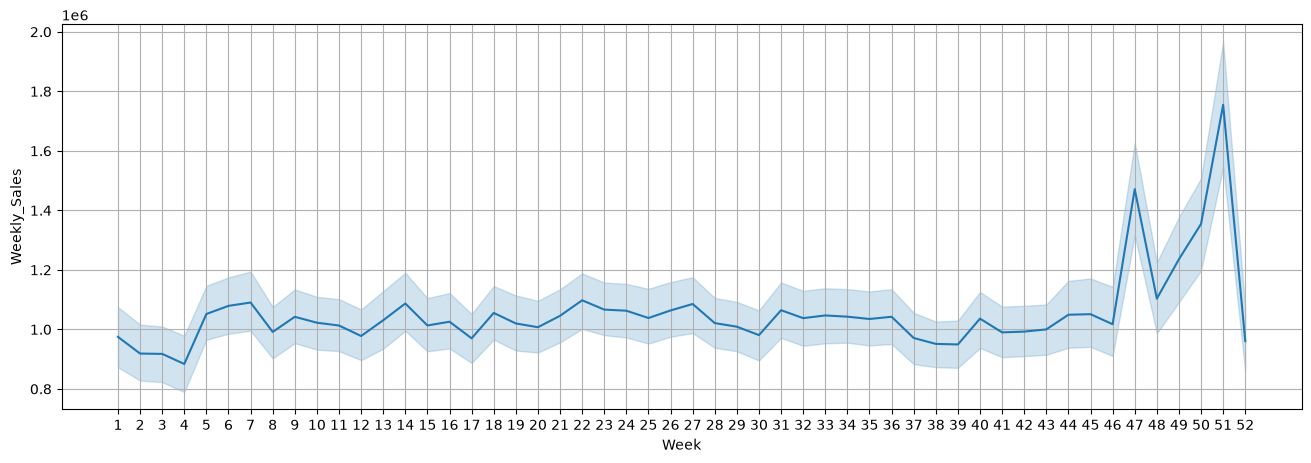

In [57]:
f, ax = plt.subplots(figsize=(16,5))
sns.lineplot(x='Week', y='Weekly_Sales',  data=data, ax=ax)
_ = ax.set_xticks(range(1,53))
plt.grid()

### 8.1 Variable « fêtes de fin d'année »

Le graphique montre des pics en semaine 47 (Thanksgiving / Black Friday) et en semaines 49 à 51 (avant Noël). On crée une variable `End_of_year_holidays` qui vaut 1 sur ces semaines et 0 sinon.

In [58]:
data['End_of_year_holidays'] = data['Week'].isin([47, 49, 50, 51])
data['End_of_year_holidays'] = data['End_of_year_holidays'].replace({True:1, False:0}) 

C:\Users\bibaw\AppData\Local\Temp\ipykernel_11788\3451560644.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['End_of_year_holidays'] = data['End_of_year_holidays'].replace({True:1, False:0})


### 8.2 Modèle 3 : avec la variable de fêtes de fin d'année

In [59]:
model, RSS, RSE, R2app, R2test = my_linear_regression(data, 'Weekly_Sales')
print("R2 sur la base d'apprentissage", round(R2app, 4))
print("R2 sur la base de test", round(R2test, 4))
print("RSE (apprentissage)", round(RSE, 0))

R2 sur la base d'apprentissage 0.9535
R2 sur la base de test 0.9413
RSE (apprentissage) 121278.0


In [60]:
# Influence de la nouvelle variable : coefficient appris (en $ de ventes hebdomadaires)
coefs = pd.Series(model.coef_, index=data.drop(columns=['Weekly_Sales']).columns)
print("Coefficient de End_of_year_holidays :", round(coefs['End_of_year_holidays'], 0))

Coefficient de End_of_year_holidays : 460787.0


**Résultat :** R² ≈ **0,954** en apprentissage et ≈ **0,941** en test. Une seule variable bien choisie fait encore gagner plus de 2 points de R² et réduit l'erreur (RSE ≈ 121 000 $ contre 148 000 $). Son coefficient indique qu'une semaine de fêtes de fin d'année rapporte en moyenne **≈ 460 000 $ de ventes supplémentaires** par magasin.

---

## Conclusion

| Modèle | R² apprentissage | R² test |
|---|---|---|
| Variables quantitatives seules | 0,675 | 0,658 |
| + date + one-hot (Store, Type, IsHoliday) | 0,930 | 0,918 |
| + variable `End_of_year_holidays` | **0,954** | **0,941** |

- La **taille du magasin** est le premier facteur des ventes (corrélation 0,81). Les variables économiques (chômage, CPI, prix du carburant) ont peu d'influence.
- L'**identité du magasin** (encodage one-hot) apporte le plus grand gain de performance : chaque magasin a son propre niveau de ventes.
- La **saisonnalité de fin d'année** est le principal effet temporel. `IsHoliday` est trop grossière pour la capter, alors qu'une variable ciblée sur les semaines 47 et 49 à 51 l'exploite directement.
- Avec une simple régression linéaire et un peu de *feature engineering*, on explique **94 % de la variance** des ventes hebdomadaires sur des données jamais vues.

**Pistes d'amélioration :** validation croisée temporelle (entraîner sur le passé, tester sur le futur), modèles non linéaires (Random Forest, Gradient Boosting), variables de décalage (ventes des semaines précédentes).

## 9 - Visualisation des résultats

Pour visualiser la performance du modèle final, on le réentraîne sur la base d'apprentissage (même découpage 80 / 20 que précédemment) et on compare ses prédictions aux ventes réelles de la base de test.

In [61]:
X = data.drop(columns=['Weekly_Sales'])
y = data['Weekly_Sales']
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=SEED)
final_model = LinearRegression().fit(Xtrain, ytrain)
ypred = final_model.predict(Xtest)
print("R2 sur la base de test :", round(final_model.score(Xtest, ytest), 4))

R2 sur la base de test : 0.9413


### 9.1 Progression des modèles

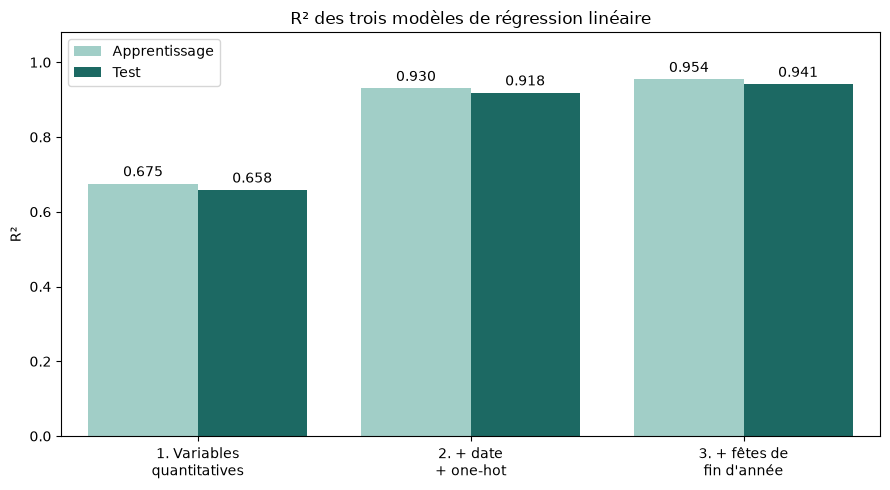

In [62]:
scores = pd.DataFrame({
    'Modèle': ['1. Variables\nquantitatives', '2. + date\n+ one-hot', '3. + fêtes de\nfin d\'année'],
    'Apprentissage': [0.675, 0.930, 0.954],
    'Test': [0.658, 0.918, 0.941],
}).melt(id_vars='Modèle', var_name='Base', value_name='R²')

f, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=scores, x='Modèle', y='R²', hue='Base', palette=['#99d5cc', '#0f766e'], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3)
ax.set_ylim(0, 1.08)
ax.set_xlabel('')
ax.set_title('R² des trois modèles de régression linéaire')
ax.legend(title='', loc='upper left')
plt.tight_layout()
plt.show()

### 9.2 Prédictions contre ventes réelles (base de test)

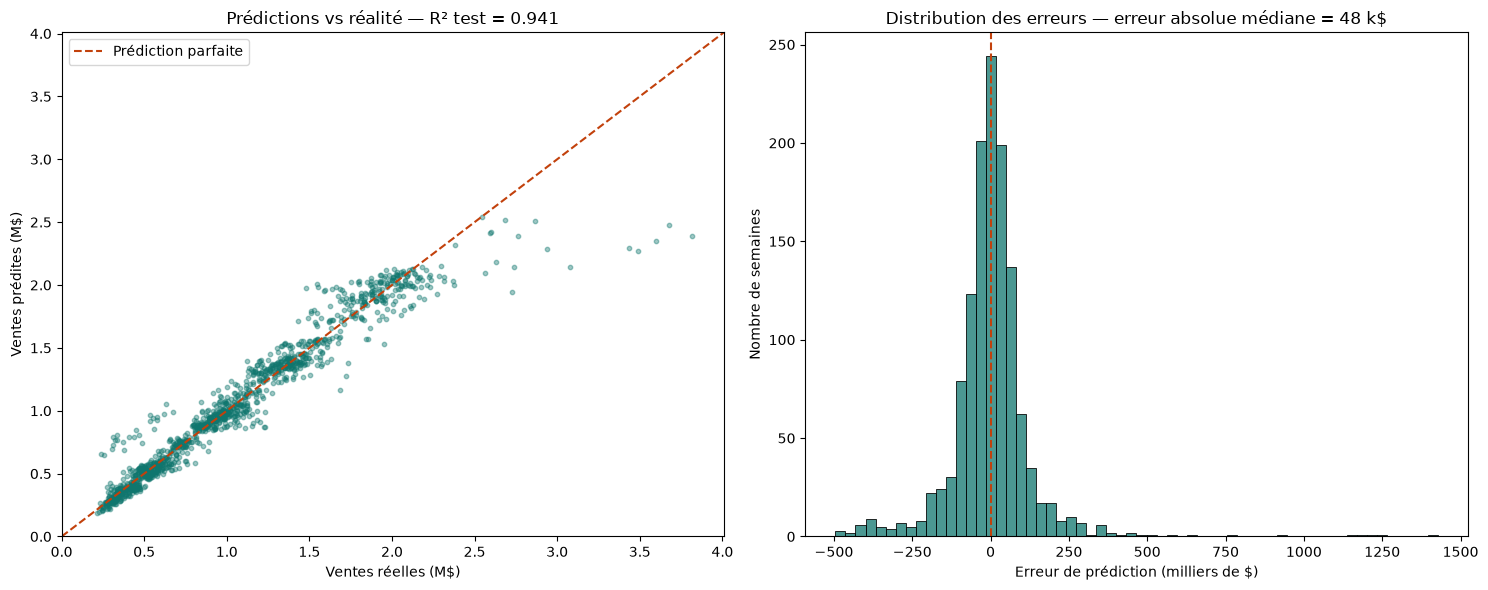

In [63]:
f, axes = plt.subplots(1, 2, figsize=(15, 6))

ax = axes[0]
ax.scatter(ytest / 1e6, ypred / 1e6, s=10, alpha=0.4, color='#0f766e')
lim = [0, max(ytest.max(), ypred.max()) / 1e6 * 1.05]
ax.plot(lim, lim, '--', color='#c2410c', label='Prédiction parfaite')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Ventes réelles (M$)')
ax.set_ylabel('Ventes prédites (M$)')
ax.set_title(f'Prédictions vs réalité — R² test = {final_model.score(Xtest, ytest):.3f}')
ax.legend()

ax = axes[1]
residus = (ytest - ypred) / 1e3
sns.histplot(residus, bins=60, color='#0f766e', ax=ax)
ax.axvline(0, color='#c2410c', linestyle='--')
ax.set_xlabel('Erreur de prédiction (milliers de $)')
ax.set_ylabel('Nombre de semaines')
ax.set_title(f'Distribution des erreurs — erreur absolue médiane = {residus.abs().median():.0f} k$')

plt.tight_layout()
plt.show()

### 9.3 Exemple sur un magasin

Ventes réelles et prédites semaine par semaine pour le magasin n°20, l'un des plus gros du réseau.

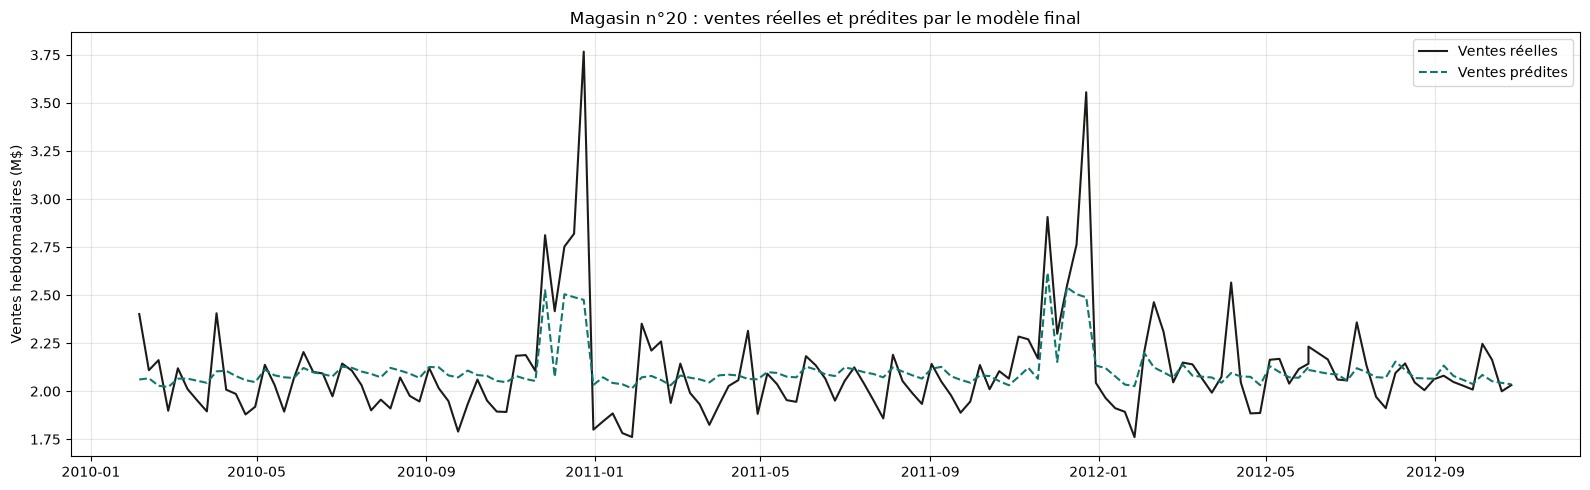

In [64]:
store = 20
mask = data[f'Store_{store}'] == 1
suivi = pd.DataFrame({
    'Date': df2.loc[mask, 'Date'],
    'Ventes réelles': data.loc[mask, 'Weekly_Sales'] / 1e6,
    'Ventes prédites': final_model.predict(X[mask]) / 1e6,
}).sort_values('Date')

f, ax = plt.subplots(figsize=(16, 5))
ax.plot(suivi['Date'], suivi['Ventes réelles'], color='#1d1b18', linewidth=1.5, label='Ventes réelles')
ax.plot(suivi['Date'], suivi['Ventes prédites'], color='#0f766e', linewidth=1.5, linestyle='--', label='Ventes prédites')
ax.set_ylabel('Ventes hebdomadaires (M$)')
ax.set_title(f'Magasin n°{store} : ventes réelles et prédites par le modèle final')
ax.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Constat :** le modèle retrouve le niveau de ventes du magasin et place les pics de fin d'année au bon moment, mais il en **sous-estime nettement l'ampleur** (≈ 2,5 M$ prédits contre 3,8 M$ réels à Noël 2010). On retrouve ce biais sur le nuage de points : les plus grosses semaines sont sous-estimées.

**Explication :** dans une régression linéaire, l'effet « fêtes de fin d'année » est un montant fixe (≈ +460 000 $) identique pour tous les magasins, alors qu'en réalité il est proportionnel à la taille du magasin. **Pistes :** ajouter une interaction `End_of_year_holidays × Size`, prédire le logarithme des ventes (effets multiplicatifs), ou utiliser un modèle non linéaire (Gradient Boosting).